# MLP_JK_01 — Baseline MLP vs. mean predictor and ridge

**The question**

Can a small neural network (an MLP) predict the expression of the top-50 genes from the GenBio-PathFM embeddings better than ridge regression, under the same 4-fold patient split?

| Condition | Input | Model |
|---|---|---|
| `mean predictor` | nothing (predicts the training mean of each gene) | — |
| `ridge raw` | each spot's own embedding (4,608 numbers) | StandardScaler + PCA 256 + ridge, copied from Notebook 5 |
| `MLP raw` | each spot's own embedding (4,608 numbers) | StandardScaler + MLP |
| `MLP center+mean-3x3` | the spot's embedding next to the average of its 3×3 neighborhood (9,216 numbers) | StandardScaler + MLP |

The best ridge from Notebook 5 (`ridge center+mean-3x3`, pooled PCC 0.203) is shown as a reference row, read from Notebook 5's saved scores (not re-run).

**Checks and rules (decided before running)**
- `ridge raw` must reproduce Notebook 5 (pooled PCC ≈ 0.187). If it doesn't, the notebook stops at Step 5.
- Everything learned (scaler, genes, early-stopping epoch) uses **training patients only**. Early stopping uses a held-out group of training patients (the **validation** patients), never the test fold.
- **Choosing the best MLP setup** uses validation scores only: highest validation PCC, and validation NRMSE no worse than the mean predictor's on the same validation patients. Test scores are reported but not used to choose.

**Reads** `~/JHU/BDD/datasets/BDD_HEST` and Notebook 5's saved scores in `~/JHU/BDD/Experiments/smoothing_control/`.
**Saves** to `~/JHU/BDD/MLP_JK/results/MLP_JK_01/` and adds rows to `~/JHU/BDD/MLP_JK/results/all_results.csv`.

In [1]:
import os
import copy
import json
import time
import datetime
import numpy as np
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.neighbors import NearestNeighbors

## Settings

**Paths**
- `NOTEBOOK_5_DIR`: Notebook 5's saved scores, used to check the ridge rerun and for the best-ridge reference row.
- `LOG_RESULTS`: whether this notebook adds its rows to `all_results.csv`.

**Evaluation** (copied from Notebook 5, so the numbers are comparable)
- `N_FOLDS = 4` patient folds, `N_GENES = 50` top-variance genes, `MIN_TEST_SD = 0.05` (genes that barely vary in a test set are left out of NRMSE), `SEED = 0`.
- `N_PCS`, `N_INNER_FOLDS`, `ALPHAS`: the ridge settings (PCA to 256 components, λ per gene from 40 values, chosen with a 3-group patient split of the training patients).
- `NEIGHBOR_DISTANCE = 1.8` spot spacings = the 3×3 square.

**MLP**
- `MLP_CONDITIONS`: which inputs to train an MLP on.
- `N_VAL_GROUPS = 4`: the training patients are split into 4 groups by patient, and one group (about 4 of the ~17 training patients) is the validation set for early stopping.
- `HIDDEN_SIZE`, `DROPOUT`: the size of the hidden layer and the share of hidden units switched off at random during training. Dropout makes it harder to memorize the training patients.
- `LEARNING_RATE`, `WEIGHT_DECAY`: Adam's step size, and a small pull of the weights toward zero (the same idea as ridge's λ).
- `BATCH_SIZE`, `MAX_EPOCHS`, `PATIENCE`: spots per training step, the most passes over the data, and how many epochs without a better validation loss before stopping.
- `RETRAIN_ON_ALL_TRAINING`: after early stopping finds the best number of epochs, train a fresh model on **all** training patients for that many epochs, so the final model sees as many patients as ridge did.

These MLP numbers were fixed before running, not tuned.

In [2]:
DATA_DIR = os.path.expanduser("~/JHU/BDD/datasets/BDD_HEST")
NOTEBOOK_5_DIR = os.path.expanduser("~/JHU/BDD/Experiments/smoothing_control")
MLP_DIR = os.path.expanduser("~/JHU/BDD/MLP_JK")
NOTEBOOK_NAME = "MLP_JK_01"
LOG_RESULTS = True
MLP_CONDITIONS = ["raw", "center+mean-3x3"]
OUT_DIR = os.path.join(MLP_DIR, "results", NOTEBOOK_NAME)
RESULTS_LOG = os.path.join(MLP_DIR, "results", "all_results.csv")

N_FOLDS = 4
N_INNER_FOLDS = 3
N_GENES = 50
N_PCS = 256
ALPHAS = np.logspace(-2, 7, 40)
MIN_TEST_SD = 0.05
SEED = 0
NEIGHBOR_DISTANCE = 1.8

N_VAL_GROUPS = 4
HIDDEN_SIZE = 256
DROPOUT = 0.3
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 10
RETRAIN_ON_ALL_TRAINING = True

The device is the Apple GPU (`mps`) if it's available, otherwise the CPU. Seeds are fixed for numpy and torch. (The Apple GPU isn't perfectly deterministic, so a rerun can differ in the third decimal.)

In [3]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

np.random.seed(SEED)
torch.manual_seed(SEED)

EXPRESSION_DIR = os.path.join(DATA_DIR, "expression")
EMBEDDING_DIR = os.path.join(DATA_DIR, "embeddings")
os.makedirs(OUT_DIR, exist_ok=True)


def save_figure(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")

Device: mps


## Step 1. Load embeddings and expression (copied from Notebook 5)

Each section's embedding file must list the same barcodes, in the same order, as the spot table, and each expression matrix must have one row per spot and one column per gene. The `assert` lines stop the notebook if not.

In [4]:
spot_table = pd.read_csv(os.path.join(DATA_DIR, "spot_table.csv"))
with open(os.path.join(DATA_DIR, "genes.txt")) as f:
    all_genes = np.array(f.read().split())

X_parts = []
Y_parts = []
spot_parts = []

for sample_id in spot_table["sample_id"].unique():
    section_spots = spot_table[spot_table["sample_id"] == sample_id].sort_values("row_in_sample")

    saved = np.load(os.path.join(EMBEDDING_DIR, f"{sample_id}.npz"), allow_pickle=True)
    assert np.array_equal(saved["barcode"], section_spots["barcode"].to_numpy()), \
        f"{sample_id}: embedding rows don't match the spot table"

    expression = scipy.sparse.load_npz(os.path.join(EXPRESSION_DIR, f"{sample_id}.npz"))
    assert expression.shape == (len(section_spots), len(all_genes)), \
        f"{sample_id}: expression shape doesn't match the spot table and genes.txt"

    X_parts.append(saved["embeddings"].astype(np.float32))
    Y_parts.append(expression)
    spot_parts.append(section_spots)

X_raw = np.concatenate(X_parts, axis=0)
Y = scipy.sparse.vstack(Y_parts).tocsc()
spots = pd.concat(spot_parts, ignore_index=True)
del X_parts, Y_parts
patient_array = spots["patient"].to_numpy()
section_array = spots["sample_id"].to_numpy()

print("X (embeddings):", X_raw.shape)
print("Y (log1p expression):", Y.shape)
print("Sections:", spots["sample_id"].nunique(), " Patients:", spots["patient"].nunique())

X (embeddings): (30600, 4608)
Y (log1p expression): (30600, 11787)
Sections: 68  Patients: 23


## Step 2. Neighborhoods and the center+mean-3x3 input (copied from Notebook 5)

For each section:
1. **Spot spacing** = median distance from a spot to its closest other spot.
2. A spot's **neighborhood** = every spot on the same section within 1.8 × spacing, **including the spot itself**. That is the 3×3 square.
3. The averaged embedding = the plain mean over the neighborhood. Spots at the tissue edge have fewer than 9 and are averaged over what exists.

`center+mean-3x3` puts the spot's own embedding next to its neighborhood average: 4,608 + 4,608 = 9,216 numbers. The averages use images only, from the same section.

In [5]:
def find_neighborhoods(max_distance):
    neighborhoods = [None] * len(spots)
    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)
        for i, nearby in enumerate(nearby_lists):
            neighborhoods[rows[i]] = rows[nearby]
    return neighborhoods


def neighbor_mean(X, neighborhoods):
    X_smoothed = np.zeros_like(X)
    for i, nearby in enumerate(neighborhoods):
        X_smoothed[i] = X[nearby].mean(axis=0)
    return X_smoothed


neighborhoods_3x3 = find_neighborhoods(NEIGHBOR_DISTANCE)
sizes = np.array([len(n) for n in neighborhoods_3x3])
print(f"3x3: spots per neighborhood (incl. itself) mean {sizes.mean():.2f}, "
      f"min {sizes.min()}, max {sizes.max()} | full (9): {np.mean(sizes == 9):.1%}")


def make_embeddings(condition):
    if condition == "raw":
        return X_raw
    if condition == "center+mean-3x3":
        return np.concatenate([X_raw, neighbor_mean(X_raw, neighborhoods_3x3)], axis=1)
    raise ValueError(f"unknown condition {condition}")

3x3: spots per neighborhood (incl. itself) mean 8.30, min 1, max 10 | full (9): 70.7%


## Step 3. Patient folds (copied from Notebook 5)

`GroupKFold` puts every spot of a patient in the same fold, so the test patients are never seen in training. Each fold is the test set once.

In [6]:
fold_of_spot = np.zeros(len(spots), dtype=int)
splitter = GroupKFold(n_splits=N_FOLDS)
for fold, (train_index, test_index) in enumerate(splitter.split(X_raw, groups=patient_array)):
    fold_of_spot[test_index] = fold

for fold in range(N_FOLDS):
    print(f"fold {fold}: {np.sum(fold_of_spot == fold)} test spots | {sorted(np.unique(patient_array[fold_of_spot == fold]))}")

fold 0: 7625 test spots | ['BC23209', 'BC23803', 'BC23810', 'BC23895', 'BC23901', 'BC23903']
fold 1: 7950 test spots | ['BC23268', 'BC23287', 'BC23377', 'BC23450', 'BC23506', 'BC24220']
fold 2: 7876 test spots | ['BC23269', 'BC23270', 'BC23277', 'BC23508', 'BC23567', 'BC24105']
fold 3: 7149 test spots | ['BC23272', 'BC23288', 'BC23944', 'BC24044', 'BC24223']


## Step 4. Gene choice and scoring (copied from Notebook 5)

**`choose_genes`**: the 50 genes with the highest variance across the **training** spots of a fold.

**`score_model`** gives two kinds of score for every gene:
- **Pooled**: over all test spots of the fold together. **PCC** = correlation between predicted and true expression. **NRMSE** = prediction error divided by the gene's spread (SD) in the test spots.
- **Within patient**: the same, but inside one test patient at a time, then averaged. This asks whether the model ranks spots correctly *within* a tissue, not just whether it gets the patient's overall level right.

The **mean predictor** predicts the training mean for every spot. Its PCC is undefined (the prediction is constant), and its NRMSE is the bar any useful model should get under.

In [7]:
def choose_genes(train_index):
    Y_train = Y[train_index]
    mean = np.asarray(Y_train.mean(axis=0)).ravel()
    mean_of_squares = np.asarray(Y_train.multiply(Y_train).mean(axis=0)).ravel()
    variance = mean_of_squares - mean ** 2
    return np.argsort(variance)[::-1][:N_GENES]


def pcc(a, b):
    if np.std(a) < 1e-6 or np.std(b) < 1e-6:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def score_model(model_name, fold_results, prediction_key):
    pooled_rows = []
    within_rows = []
    for r in fold_results:
        y_true = r["y_test"]
        y_pred = r[prediction_key]
        test_patients = patient_array[r["test_index"]]

        for g, gene in enumerate(r["genes"]):
            sd = np.std(y_true[:, g])
            rmse = np.sqrt(np.mean((y_true[:, g] - y_pred[:, g]) ** 2))
            pooled_rows.append({
                "model": model_name, "fold": r["fold"], "gene": gene,
                "PCC": pcc(y_true[:, g], y_pred[:, g]),
                "NRMSE": rmse / sd if sd >= MIN_TEST_SD else np.nan,
                "alpha": r["alpha"][g] if prediction_key == "y_pred" else np.nan,
            })

        for patient in np.unique(test_patients):
            rows = test_patients == patient
            for g, gene in enumerate(r["genes"]):
                t = y_true[rows, g]
                p = y_pred[rows, g]
                sd = np.std(t)
                if sd < MIN_TEST_SD:
                    continue
                centered_mse = np.mean(((t - t.mean()) - (p - p.mean())) ** 2)
                within_rows.append({
                    "model": model_name, "fold": r["fold"], "patient": patient, "gene": gene,
                    "PCC_within": pcc(t, p),
                    "NRMSE_within": np.sqrt(np.mean((t - p) ** 2)) / sd,
                    "NRMSE_centered": np.sqrt(centered_mse) / sd,
                })
    return pd.DataFrame(pooled_rows), pd.DataFrame(within_rows)

## Step 5. Ridge on raw embeddings (copied from Notebook 5), and the reproduction check

Inside each fold, using **training spots only**: choose the top-50 genes, fit StandardScaler + PCA 256, choose λ per gene with a 3-group patient split of the training patients, fit ridge, predict the test patients. The mean predictor comes from the same fold (the training mean of each gene).

Then the **check**: the pooled PCC and NRMSE must match Notebook 5's `ridge raw` (0.187 / 1.092). If they don't, the `assert` stops the notebook here, because then the setup isn't the same and nothing below would be comparable.

In [8]:
def choose_alpha_per_gene(P_train, y_train, inner_groups):
    n_inner = min(N_INNER_FOLDS, len(np.unique(inner_groups)))
    inner_splits = GroupKFold(n_splits=n_inner).split(P_train, groups=inner_groups)

    errors = np.zeros((len(ALPHAS), y_train.shape[1]))
    for inner_train, inner_val in inner_splits:
        for a, alpha in enumerate(ALPHAS):
            model = Ridge(alpha=alpha)
            model.fit(P_train[inner_train], y_train[inner_train])
            prediction = model.predict(P_train[inner_val])
            errors[a] += np.mean((prediction - y_train[inner_val]) ** 2, axis=0)

    best = np.argmin(errors, axis=0)
    return ALPHAS[best]


def fit_and_predict(P_train, y_train, P_test, alpha_per_gene):
    y_pred = np.zeros((P_test.shape[0], y_train.shape[1]))
    for alpha in np.unique(alpha_per_gene):
        genes_with_this_alpha = np.where(alpha_per_gene == alpha)[0]
        model = Ridge(alpha=alpha)
        model.fit(P_train, y_train[:, genes_with_this_alpha])
        y_pred[:, genes_with_this_alpha] = model.predict(P_test).reshape(len(P_test), -1)
    return y_pred


def run_ridge_fold(X, fold):
    is_test = fold_of_spot == fold
    train_index = np.where(~is_test)[0]
    test_index = np.where(is_test)[0]

    gene_index = choose_genes(train_index)
    y_train = Y[train_index][:, gene_index].toarray()
    y_test = Y[test_index][:, gene_index].toarray()

    scaler = StandardScaler(copy=False)
    Z_train = scaler.fit_transform(X[train_index])
    Z_test = scaler.transform(X[test_index])

    pca = PCA(n_components=N_PCS, random_state=SEED, copy=False)
    P_train = pca.fit_transform(Z_train)
    P_test = pca.transform(Z_test)

    alpha_per_gene = choose_alpha_per_gene(P_train, y_train, patient_array[train_index])
    y_pred = fit_and_predict(P_train, y_train, P_test, alpha_per_gene)
    y_mean = np.tile(y_train.mean(axis=0), (len(test_index), 1))

    return {
        "fold": fold,
        "test_index": test_index,
        "genes": all_genes[gene_index],
        "y_test": y_test,
        "y_pred": y_pred,
        "y_mean": y_mean,
        "alpha": alpha_per_gene,
    }


start_time = time.time()
ridge_results = []
for fold in range(N_FOLDS):
    ridge_results.append(run_ridge_fold(X_raw, fold))
    print(f"ridge raw fold {fold} done  ({(time.time() - start_time) / 60:.1f} min)", flush=True)

ridge raw fold 0 done  (0.1 min)


ridge raw fold 1 done  (0.2 min)


ridge raw fold 2 done  (0.3 min)


ridge raw fold 3 done  (0.4 min)


In [9]:
mean_pooled, mean_within = score_model("mean predictor", ridge_results, "y_mean")
ridge_pooled, ridge_within = score_model("ridge raw", ridge_results, "y_pred")

notebook_5_summary = pd.read_csv(os.path.join(NOTEBOOK_5_DIR, "summary.csv")).set_index("model")
our_pcc = ridge_pooled["PCC"].mean()
our_nrmse = ridge_pooled["NRMSE"].mean()
notebook_5_pcc = notebook_5_summary.loc["ridge raw", "pooled_PCC"]
notebook_5_nrmse = notebook_5_summary.loc["ridge raw", "pooled_NRMSE"]

print(f"ridge raw, this notebook: pooled PCC {our_pcc:.4f}, NRMSE {our_nrmse:.4f}")
print(f"ridge raw, Notebook 5:    pooled PCC {notebook_5_pcc:.4f}, NRMSE {notebook_5_nrmse:.4f}")

assert abs(our_pcc - notebook_5_pcc) < 0.001 and abs(our_nrmse - notebook_5_nrmse) < 0.001, \
    "Ridge rerun does not reproduce Notebook 5. Stop and find out why before going further."
print("Reproduces Notebook 5.")

ridge raw, this notebook: pooled PCC 0.1868, NRMSE 1.0917
ridge raw, Notebook 5:    pooled PCC 0.1868, NRMSE 1.0917
Reproduces Notebook 5.


## Step 6. The MLP

**The network**: input → Linear(input, 256) → ReLU → Dropout → Linear(256, 50 genes). The last layer has no activation because this is regression: the output can be any number.

**Before the network**, inside each training run:
- **Input scaling**: a `StandardScaler` is fit on the training spots. Its mean and SD are moved to the GPU and applied to each batch, so the whole embedding matrix is only copied to the GPU once.
- **Gene scaling**: each of the 50 genes is standardized with the training mean and SD, so every gene counts about equally in the loss (ridge's errors were also per gene). Predictions are converted back to log1p units before scoring.

**`train_mlp`**: Adam, MSE loss, mini-batches of 256 spots in a shuffled order each epoch.
- With validation spots: after every epoch, compute the validation loss and keep the weights from the best epoch. Stop when it hasn't improved for `PATIENCE` epochs.
- Without validation spots: train for a fixed number of epochs (used for the retrain on all training patients).

**`predict`** switches dropout off (`model.eval()`) and returns predictions in log1p units.

In [10]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(n_hidden, n_outputs),
        )

    def forward(self, x):
        return self.layers(x)


def to_device(array):
    return torch.tensor(np.asarray(array), dtype=torch.float32, device=device)


def predict(trained, X_device, rows):
    model = trained["model"]
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(rows), 2048):
            batch_rows = torch.tensor(rows[start:start + 2048], device=device)
            x = (X_device[batch_rows] - trained["x_mean"]) / trained["x_scale"]
            outputs.append(model(x).cpu().numpy())
    y_scaled = np.concatenate(outputs, axis=0)
    return y_scaled * trained["gene_sd"] + trained["gene_mean"]


def train_mlp(X, X_device, y_fold, train_rows, val_rows, n_epochs):
    torch.manual_seed(SEED)
    rng = np.random.default_rng(SEED)

    scaler = StandardScaler().fit(X[train_rows])
    gene_mean = y_fold[train_rows].mean(axis=0)
    gene_sd = y_fold[train_rows].std(axis=0)
    y_scaled = to_device((y_fold - gene_mean) / gene_sd)

    model = MLP(X.shape[1], HIDDEN_SIZE, N_GENES, DROPOUT).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_function = nn.MSELoss()

    trained = {
        "model": model,
        "x_mean": to_device(scaler.mean_),
        "x_scale": to_device(scaler.scale_),
        "gene_mean": gene_mean,
        "gene_sd": gene_sd,
        "history": [],
        "best_epoch": n_epochs,
    }

    best_val_loss = np.inf
    best_weights = None
    for epoch in range(1, n_epochs + 1):
        model.train()
        shuffled = rng.permutation(train_rows)
        batch_losses = []
        for start in range(0, len(shuffled), BATCH_SIZE):
            batch_rows = torch.tensor(shuffled[start:start + BATCH_SIZE], device=device)
            x = (X_device[batch_rows] - trained["x_mean"]) / trained["x_scale"]
            loss = loss_function(model(x), y_scaled[batch_rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = np.mean(batch_losses)

        if val_rows is None:
            trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": np.nan})
            continue

        val_pred = predict(trained, X_device, val_rows)
        val_loss = np.mean(((val_pred - y_fold[val_rows]) / gene_sd) ** 2)
        trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            trained["best_epoch"] = epoch
            best_weights = copy.deepcopy(model.state_dict())
        elif epoch - trained["best_epoch"] >= PATIENCE:
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return trained

## Step 7. One fold, start to finish

Everything that learns from data uses the fold's **training patients only**:

| Step | Uses |
|---|---|
| Top-50 genes | all training spots (same function as ridge, so the genes match) |
| Validation split | the training patients split into 4 groups by patient; one group is validation |
| Scaler + early-stopping model | the other ~3/4 of training patients; validation picks the epoch |
| Validation scores (used to choose between setups) | the early-stopping model on the validation patients |
| Final model | a fresh model on **all** training patients, for the best epoch count |
| Test patients | used **once**, to score the final model |

As a guard, the test spots' expression is set to `NaN` in the array the training loop reads. If a test spot were ever used in training by mistake, the loss would turn into `NaN` right away.

The validation results use the same layout as the test results, so `score_model` can score them too. The validation mean predictor is the mean of the patients the early-stopping model trained on.

In [11]:
def split_validation(train_index):
    groups = patient_array[train_index]
    inner_train, inner_val = next(GroupKFold(n_splits=N_VAL_GROUPS).split(train_index, groups=groups))
    return train_index[inner_train], train_index[inner_val]


def run_mlp_fold(X, X_device, fold):
    is_test = fold_of_spot == fold
    train_index = np.where(~is_test)[0]
    test_index = np.where(is_test)[0]

    gene_index = choose_genes(train_index)
    genes = all_genes[gene_index]
    y_fold = Y[:, gene_index].toarray()
    y_fold[test_index] = np.nan
    no_alpha = np.full(N_GENES, np.nan)

    fit_rows, val_rows = split_validation(train_index)
    early = train_mlp(X, X_device, y_fold, fit_rows, val_rows, MAX_EPOCHS)
    val_pred = predict(early, X_device, val_rows)
    val_result = {
        "fold": fold,
        "test_index": val_rows,
        "genes": genes,
        "y_test": y_fold[val_rows],
        "y_pred": val_pred,
        "y_mean": np.tile(y_fold[fit_rows].mean(axis=0), (len(val_rows), 1)),
        "alpha": no_alpha,
    }

    if RETRAIN_ON_ALL_TRAINING:
        final = train_mlp(X, X_device, y_fold, train_index, None, early["best_epoch"])
    else:
        final = early

    test_result = {
        "fold": fold,
        "test_index": test_index,
        "genes": genes,
        "y_test": Y[test_index][:, gene_index].toarray(),
        "y_pred": predict(final, X_device, test_index),
        "alpha": no_alpha,
    }
    history = pd.DataFrame(early["history"])
    history["fold"] = fold
    history["best_epoch"] = early["best_epoch"]
    history["validation_patients"] = len(np.unique(patient_array[val_rows]))
    return test_result, val_result, history

## Step 8. Train and test the MLP on every fold

For each input, the embedding matrix is built and copied to the GPU once, then used for all 4 folds. It's deleted before the next input to free memory.

In [12]:
mlp_results = {}
mlp_val_results = {}
loss_tables = []
start_time = time.time()

for condition in MLP_CONDITIONS:
    X = make_embeddings(condition)
    X_device = to_device(X)
    mlp_results[condition] = []
    mlp_val_results[condition] = []
    for fold in range(N_FOLDS):
        test_result, val_result, history = run_mlp_fold(X, X_device, fold)
        mlp_results[condition].append(test_result)
        mlp_val_results[condition].append(val_result)
        history["condition"] = condition
        loss_tables.append(history)
        print(f"MLP {condition:16s} fold {fold}: best epoch {history['best_epoch'].iloc[0]:3d} "
              f"({(time.time() - start_time) / 60:.1f} min)", flush=True)
    del X, X_device
    if device.type == "mps":
        torch.mps.empty_cache()

loss_history = pd.concat(loss_tables, ignore_index=True)
print("All MLP runs done.")

MLP raw              fold 0: best epoch   6 (0.1 min)


MLP raw              fold 1: best epoch   6 (0.2 min)


MLP raw              fold 2: best epoch   5 (0.3 min)


MLP raw              fold 3: best epoch  10 (0.5 min)


MLP center+mean-3x3  fold 0: best epoch  31 (1.0 min)


MLP center+mean-3x3  fold 1: best epoch  15 (1.3 min)


MLP center+mean-3x3  fold 2: best epoch   3 (1.4 min)


MLP center+mean-3x3  fold 3: best epoch   3 (1.6 min)


All MLP runs done.


## Step 9. Validation scores and the choice of the best MLP setup

These scores use **validation patients only** (training patients held out from the early-stopping model). The choice is made here, before looking at test scores:
1. Keep only setups whose validation NRMSE is **no worse than the mean predictor's** on the same validation patients.
2. Of those, pick the one with the **highest validation PCC**.

In [13]:
val_pooled_tables = []
first_condition = MLP_CONDITIONS[0]
p, _ = score_model("mean predictor", mlp_val_results[first_condition], "y_mean")
val_pooled_tables.append(p)
for condition in MLP_CONDITIONS:
    p, _ = score_model(f"MLP {condition}", mlp_val_results[condition], "y_pred")
    val_pooled_tables.append(p)
val_pooled = pd.concat(val_pooled_tables, ignore_index=True)

val_mean_nrmse = val_pooled.loc[val_pooled["model"] == "mean predictor", "NRMSE"].mean()
val_rows = []
for condition in MLP_CONDITIONS:
    p = val_pooled[val_pooled["model"] == f"MLP {condition}"]
    val_rows.append({
        "condition": condition,
        "val_PCC": p["PCC"].mean(),
        "val_NRMSE": p["NRMSE"].mean(),
        "val_mean_predictor_NRMSE": val_mean_nrmse,
        "passes_NRMSE_rule": p["NRMSE"].mean() <= val_mean_nrmse,
    })
validation_summary = pd.DataFrame(val_rows)
print(validation_summary.round(4).to_string(index=False))

eligible = validation_summary[validation_summary["passes_NRMSE_rule"]]
if len(eligible) == 0:
    chosen_condition = None
    print("\nNo MLP setup passes the NRMSE rule on validation.")
else:
    chosen_condition = eligible.sort_values("val_PCC", ascending=False).iloc[0]["condition"]
    print(f"\nChosen by validation: MLP {chosen_condition}")

      condition  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes_NRMSE_rule
            raw   0.1525     1.1353                    1.1105              False
center+mean-3x3   0.1495     1.1303                    1.1105              False

No MLP setup passes the NRMSE rule on validation.


## Step 10. Test scores

All models scored on the test patients the same way. The `ridge center+mean-3x3 (Notebook 5)` row is read from Notebook 5's saved per-gene scores; the check makes sure its genes are the same as ours in every fold, so the comparison is gene for gene.

In [14]:
reference_name = "ridge center+mean-3x3 (Notebook 5)"
reference_pooled = pd.read_csv(os.path.join(NOTEBOOK_5_DIR, "pooled_gene_scores.csv"))
reference_within = pd.read_csv(os.path.join(NOTEBOOK_5_DIR, "within_patient_gene_scores.csv"))
reference_pooled = reference_pooled[reference_pooled["model"] == "ridge center+mean-3x3"].copy()
reference_within = reference_within[reference_within["model"] == "ridge center+mean-3x3"].copy()
reference_pooled["model"] = reference_name
reference_within["model"] = reference_name

for r in ridge_results:
    reference_genes = set(reference_pooled.loc[reference_pooled["fold"] == r["fold"], "gene"])
    assert reference_genes == set(r["genes"]), f"fold {r['fold']}: Notebook 5 genes differ"
print("Genes match Notebook 5 in every fold.")

pooled_tables = [mean_pooled, ridge_pooled, reference_pooled]
within_tables = [mean_within, ridge_within, reference_within]
for condition in MLP_CONDITIONS:
    p, w = score_model(f"MLP {condition}", mlp_results[condition], "y_pred")
    pooled_tables.append(p)
    within_tables.append(w)
pooled = pd.concat(pooled_tables, ignore_index=True)
within = pd.concat(within_tables, ignore_index=True)

model_order = ["mean predictor", "ridge raw", reference_name] + [f"MLP {c}" for c in MLP_CONDITIONS]

Genes match Notebook 5 in every fold.


**Results table.** Pooled PCC (higher is better), pooled NRMSE (lower is better; the mean predictor's value is the bar to get under), within-patient PCC (higher is better). The validation columns are the ones used to choose; they are empty for models that don't have a validation run.

In [15]:
summary_rows = []
for model_name in model_order:
    p = pooled[pooled["model"] == model_name]
    w = within[within["model"] == model_name]
    row = {
        "model": model_name,
        "pooled_PCC": p["PCC"].mean(),
        "pooled_NRMSE": p["NRMSE"].mean(),
        "within_PCC": w["PCC_within"].mean(),
        "within_NRMSE": w["NRMSE_within"].mean(),
        "val_PCC": np.nan,
        "val_NRMSE": np.nan,
    }
    if model_name.startswith("MLP "):
        v = validation_summary[validation_summary["condition"] == model_name[4:]].iloc[0]
        row["val_PCC"] = v["val_PCC"]
        row["val_NRMSE"] = v["val_NRMSE"]
    summary_rows.append(row)

summary = pd.DataFrame(summary_rows)
pd.set_option("display.width", 250)
print(summary.round(3).to_string(index=False))

mean_predictor_nrmse = summary.loc[summary["model"] == "mean predictor", "pooled_NRMSE"].iloc[0]
if chosen_condition is not None:
    chosen_nrmse = summary.loc[summary["model"] == f"MLP {chosen_condition}", "pooled_NRMSE"].iloc[0]
    print(f"\nTest check (not used to choose): MLP {chosen_condition} test NRMSE {chosen_nrmse:.3f} "
          f"vs mean predictor {mean_predictor_nrmse:.3f} -> "
          f"{'no worse' if chosen_nrmse <= mean_predictor_nrmse else 'WORSE'}")

                             model  pooled_PCC  pooled_NRMSE  within_PCC  within_NRMSE  val_PCC  val_NRMSE
                    mean predictor         NaN         1.100         NaN         1.652      NaN        NaN
                         ridge raw       0.187         1.092       0.151         1.637      NaN        NaN
ridge center+mean-3x3 (Notebook 5)       0.203         1.093       0.161         1.636      NaN        NaN
                           MLP raw       0.172         1.138       0.143         1.718    0.152      1.135
               MLP center+mean-3x3       0.216         1.114       0.156         1.663    0.150      1.130


**Per-fold table.** Each fold has different test patients, and the folds differ a lot. What matters is whether one model beats another in most folds, not just on average.

In [16]:
fold_scores = pooled.groupby(["model", "fold"]).agg(PCC=("PCC", "mean"), NRMSE=("NRMSE", "mean")).reset_index()
within_fold = within.groupby(["model", "fold"])["PCC_within"].mean().reset_index()
fold_scores = fold_scores.merge(within_fold, on=["model", "fold"])

print("Pooled PCC per fold:")
print(fold_scores.pivot(index="model", columns="fold", values="PCC").reindex(model_order).round(3).to_string())
print("\nPooled NRMSE per fold:")
print(fold_scores.pivot(index="model", columns="fold", values="NRMSE").reindex(model_order).round(3).to_string())
print("\nWithin-patient PCC per fold:")
print(fold_scores.pivot(index="model", columns="fold", values="PCC_within").reindex(model_order).round(3).to_string())

best_epochs = loss_history.groupby(["condition", "fold"])["best_epoch"].first().unstack()
print("\nBest epoch per fold (chosen on validation patients):")
print(best_epochs.to_string())

Pooled PCC per fold:


fold                                    0      1      2      3
model                                                         
mean predictor                        NaN    NaN    NaN    NaN
ridge raw                           0.158  0.313  0.090  0.186
ridge center+mean-3x3 (Notebook 5)  0.166  0.344  0.111  0.193
MLP raw                             0.166  0.286  0.110  0.126
MLP center+mean-3x3                 0.192  0.347  0.137  0.188

Pooled NRMSE per fold:
fold                                    0      1      2      3
model                                                         
mean predictor                      1.082  1.167  1.067  1.083
ridge raw                           1.099  1.117  1.102  1.049
ridge center+mean-3x3 (Notebook 5)  1.117  1.100  1.112  1.043
MLP raw                             1.165  1.120  1.153  1.115
MLP center+mean-3x3                 1.156  1.097  1.133  1.071

Within-patient PCC per fold:
fold                                    0      1      2      3


## Step 11. Plots

**Summary.** Bars are the average over folds; dots are the 4 folds. The red dashed line on the NRMSE panel is the mean predictor.

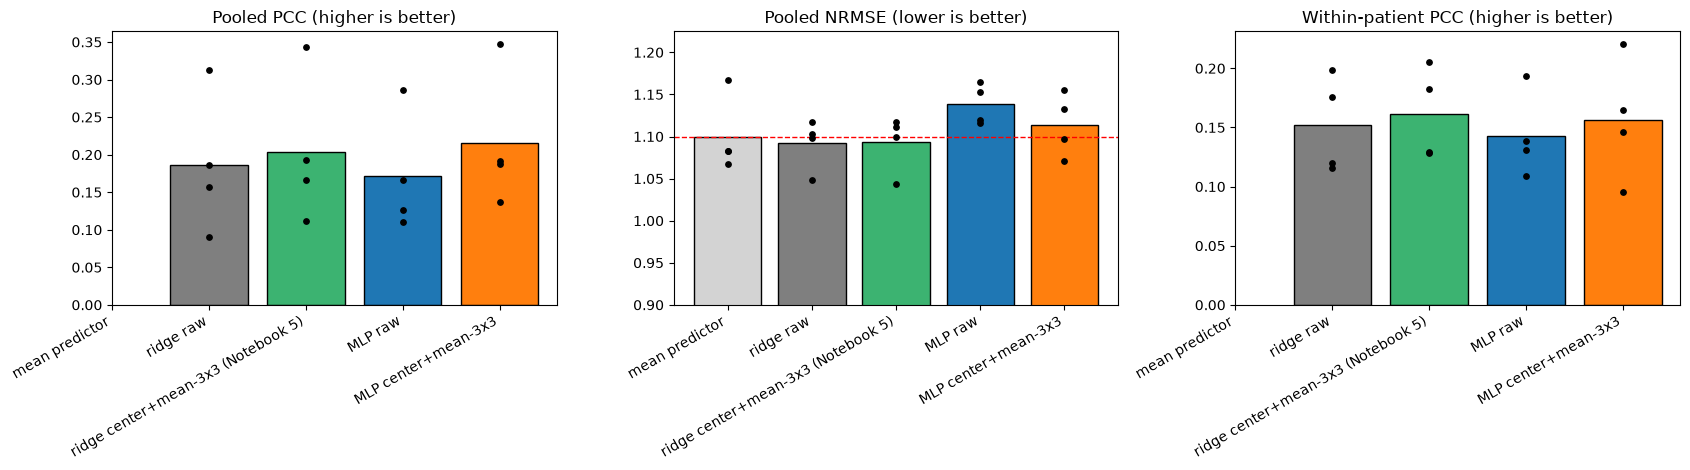

In [17]:
colors = {
    "mean predictor": "lightgrey",
    "ridge raw": "tab:gray",
    reference_name: "mediumseagreen",
    "MLP raw": "tab:blue",
    "MLP center+mean-3x3": "tab:orange",
}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
x = np.arange(len(model_order))
panels = [
    (axes[0], "PCC", "Pooled PCC (higher is better)"),
    (axes[1], "NRMSE", "Pooled NRMSE (lower is better)"),
    (axes[2], "PCC_within", "Within-patient PCC (higher is better)"),
]
for ax, column, title in panels:
    for i, model_name in enumerate(model_order):
        values = fold_scores.loc[fold_scores["model"] == model_name, column]
        if values.notna().any():
            ax.bar(i, values.mean(), color=colors[model_name], edgecolor="black")
            ax.scatter(np.full(len(values), i), values, color="black", s=15, zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=30, ha="right")
    ax.set_title(title)
axes[1].axhline(mean_predictor_nrmse, color="red", linestyle="--", linewidth=1)
axes[1].set_ylim(0.9, axes[1].get_ylim()[1])
plt.tight_layout()
save_figure("1_summary.png")
plt.show()

**Per fold.** Each line is one test fold. Lines going up or down together between two models means the difference is consistent across patients.

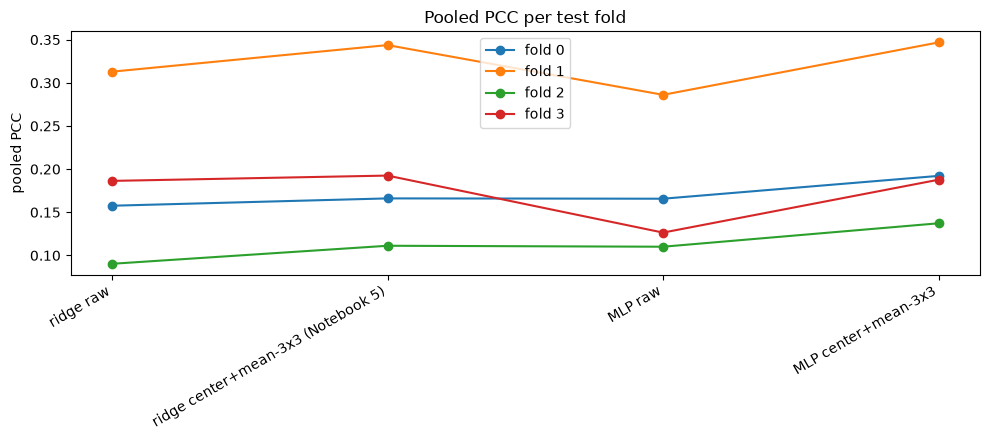

In [18]:
fold_table = fold_scores.pivot(index="model", columns="fold", values="PCC")
models_with_pcc = [m for m in model_order if m != "mean predictor"]

fig, ax = plt.subplots(figsize=(10, 4.5))
for fold in range(N_FOLDS):
    values = [fold_table.loc[m, fold] for m in models_with_pcc]
    ax.plot(range(len(models_with_pcc)), values, marker="o", label=f"fold {fold}")
ax.set_xticks(range(len(models_with_pcc)))
ax.set_xticklabels(models_with_pcc, rotation=30, ha="right")
ax.set_ylabel("pooled PCC")
ax.set_title("Pooled PCC per test fold")
ax.legend()
plt.tight_layout()
save_figure("2_per_fold.png")
plt.show()

**Training and validation loss.** Loss is the MSE on standardized genes, so 1.0 is about what the mean predictor would get. Training loss (blue) falling while validation loss (orange) rises is overfitting: the model is learning things about the training patients that don't carry over to new ones. The dashed line is the epoch early stopping chose.

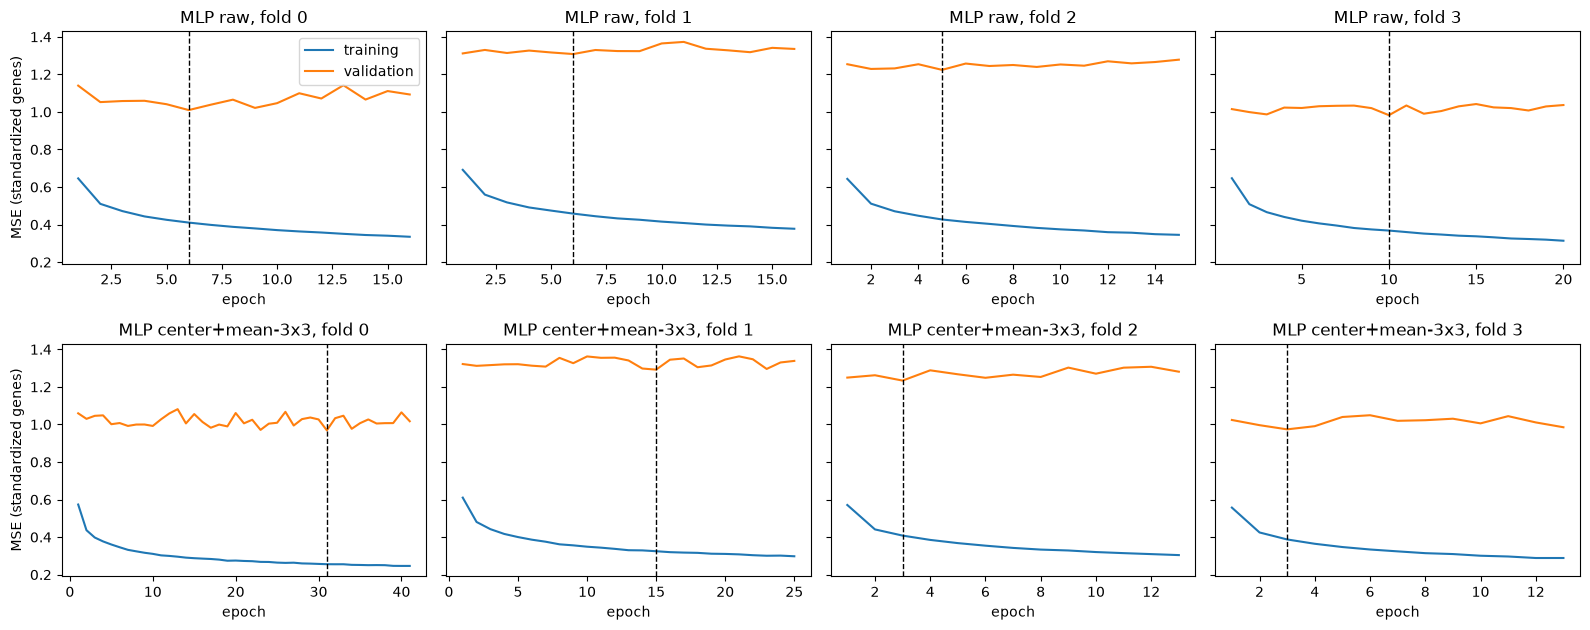

In [19]:
fig, axes = plt.subplots(len(MLP_CONDITIONS), N_FOLDS, figsize=(4 * N_FOLDS, 3.2 * len(MLP_CONDITIONS)),
                         squeeze=False, sharey=True)
for row, condition in enumerate(MLP_CONDITIONS):
    for fold in range(N_FOLDS):
        ax = axes[row, fold]
        h = loss_history[(loss_history["condition"] == condition) & (loss_history["fold"] == fold)]
        ax.plot(h["epoch"], h["train_loss"], label="training", color="tab:blue")
        ax.plot(h["epoch"], h["val_loss"], label="validation", color="tab:orange")
        ax.axvline(h["best_epoch"].iloc[0], color="black", linestyle="--", linewidth=1)
        ax.set_title(f"MLP {condition}, fold {fold}")
        ax.set_xlabel("epoch")
        if fold == 0:
            ax.set_ylabel("MSE (standardized genes)")
axes[0, 0].legend()
plt.tight_layout()
save_figure("3_loss_curves.png")
plt.show()

## Step 12. Save results and add them to the log

`all_results.csv` gets one row per condition run in this notebook (the Notebook 5 reference row isn't added, since it wasn't run here). If this notebook is run again, its old rows are replaced instead of duplicated.

In [20]:
summary.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False)
fold_scores.to_csv(os.path.join(OUT_DIR, "fold_scores.csv"), index=False)
pooled.to_csv(os.path.join(OUT_DIR, "pooled_gene_scores.csv"), index=False)
within.to_csv(os.path.join(OUT_DIR, "within_patient_gene_scores.csv"), index=False)
val_pooled.to_csv(os.path.join(OUT_DIR, "validation_gene_scores.csv"), index=False)
validation_summary.to_csv(os.path.join(OUT_DIR, "validation_summary.csv"), index=False)
loss_history.to_csv(os.path.join(OUT_DIR, "loss_history.csv"), index=False)

settings = {
    "notebook": NOTEBOOK_NAME,
    "mlp_conditions": MLP_CONDITIONS,
    "chosen_by_validation": chosen_condition,
    "neighbor_distance": NEIGHBOR_DISTANCE,
    "n_folds": N_FOLDS,
    "n_inner_folds": N_INNER_FOLDS,
    "n_genes": N_GENES,
    "n_pcs": N_PCS,
    "alphas": [float(a) for a in ALPHAS],
    "min_test_sd": MIN_TEST_SD,
    "seed": SEED,
    "n_val_groups": N_VAL_GROUPS,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "retrain_on_all_training": RETRAIN_ON_ALL_TRAINING,
    "device": str(device),
    "torch_version": torch.__version__,
}
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2)

if LOG_RESULTS:
    today = datetime.date.today().isoformat()
    log_rows = []
    for _, row in summary.iterrows():
        if row["model"] == reference_name:
            continue
        log_rows.append({
            "notebook": NOTEBOOK_NAME,
            "condition": row["model"],
            "pooled_PCC": row["pooled_PCC"],
            "within_patient_PCC": row["within_PCC"],
            "NRMSE": row["pooled_NRMSE"],
            "mean_predictor_NRMSE": mean_predictor_nrmse,
            "val_PCC": row["val_PCC"],
            "val_NRMSE": row["val_NRMSE"],
            "date": today,
        })
    new_rows = pd.DataFrame(log_rows)
    if os.path.exists(RESULTS_LOG):
        old_rows = pd.read_csv(RESULTS_LOG)
        old_rows = old_rows[old_rows["notebook"] != NOTEBOOK_NAME]
        new_rows = pd.concat([old_rows, new_rows], ignore_index=True)
    new_rows.to_csv(RESULTS_LOG, index=False)
    print(new_rows.round(4).to_string(index=False))

print("\nSaved to", OUT_DIR)
for name in sorted(os.listdir(OUT_DIR)):
    print("  ", name)

 notebook           condition  pooled_PCC  within_patient_PCC  NRMSE  mean_predictor_NRMSE  val_PCC  val_NRMSE       date
MLP_JK_01      mean predictor         NaN                 NaN 1.0997                1.0997      NaN        NaN 2026-11-06
MLP_JK_01           ridge raw      0.1868              0.1514 1.0917                1.0997      NaN        NaN 2026-11-06
MLP_JK_01             MLP raw      0.1721              0.1434 1.1382                1.0997   0.1525     1.1353 2026-11-06
MLP_JK_01 MLP center+mean-3x3      0.2160              0.1563 1.1141                1.0997   0.1495     1.1303 2026-11-06

Saved to /Users/jk/JHU/BDD/MLP_JK/results/MLP_JK_01
   1_summary.png
   2_per_fold.png
   3_loss_curves.png
   fold_scores.csv
   loss_history.csv
   pooled_gene_scores.csv
   settings.json
   summary.csv
   validation_gene_scores.csv
   validation_summary.csv
   within_patient_gene_scores.csv


## Summary in plain words

**Check first:** ridge on raw embeddings gave pooled PCC 0.1868 and NRMSE 1.0917, the same as Notebook 5. The setup is the same, so the numbers below can be compared with earlier notebooks.

### What each score means, and what we got

| Score | What it means | Good vs. bad | Mean predictor | Ridge raw | Best ridge (NB 5) | MLP raw | MLP center+mean-3x3 |
|---|---|---|---|---|---|---|---|
| **Pooled PCC** (test) | Correlation between predicted and true expression over all test spots, averaged over the 50 genes. Does the model put high-expression spots high and low ones low? | 0 = no relation, 1 = perfect. Here ~0.2 is the level to beat | — (a constant has no correlation) | 0.187 | 0.203 | 0.172 | **0.216** |
| **Within-patient PCC** (test) | The same correlation, but inside one test patient at a time. Does the model rank spots correctly *within* a tissue, not just get the patient's overall level? | Higher is better. Usually lower than pooled, because differences between patients are removed | — | 0.151 | **0.161** | 0.143 | 0.156 |
| **Pooled NRMSE** (test) | Size of the prediction error, divided by how much the gene varies. Unlike PCC, it also punishes predictions at the wrong level or with too much spread | Lower is better. Below the mean predictor = the model's numbers are closer to the truth than just guessing the average | 1.100 | **1.092** | 1.093 | 1.138 | 1.114 |
| **Validation PCC** | Pooled PCC on the held-out *training* patients. This is the score used to choose between setups | Higher is better | — | — | — | **0.152** | 0.150 |
| **Validation NRMSE** | NRMSE on the same validation patients. Must be no worse than the mean predictor there (1.111) | Lower is better | 1.111 | — | — | 1.135 | 1.130 |

### What it means

1. **The MLP on center+mean-3x3 has the highest test pooled PCC (0.216).** It beats the best ridge (0.203) in 3 of 4 folds, and it's the first model in the project above 0.21. Adding the neighborhood helped the MLP even more than it helped ridge (+0.044 vs. +0.016).
2. **Neither MLP passes the NRMSE rule.** Both have a higher NRMSE than the mean predictor, on validation and on test. They get the *order* of spots partly right (PCC), but their predicted values are too far off in level or spread. Ridge, which is heavily shrunk toward the mean, keeps its NRMSE just under the mean predictor.
3. **The MLPs overfit fast.** In the loss curves, training loss drops from ~0.6 to ~0.3 while validation loss stays flat at ~1.0–1.3 from epoch 1. The network memorizes the training patients almost right away, and early stopping is picking among noisy, nearly flat validation curves (best epochs 3–31).
4. **Validation and test disagree on which MLP is better.** By validation PCC, raw (0.152) and center+mean-3x3 (0.150) are about the same. On test, center+mean-3x3 is clearly better. With one validation group of ~4 patients per fold, the validation score is noisy.

### Decision
Following the rule (choose by validation PCC, and validation NRMSE must be no worse than the mean predictor), **no MLP setup qualifies**, so `MLP_JK_Best.ipynb` is not created from this notebook.

**What to try next:** stronger shrinkage, to bring NRMSE below the mean predictor without losing PCC. For example: more dropout and weight decay, dropout on the input, a smaller hidden layer, a lower learning rate, or averaging several seeds. A more stable validation score (e.g., averaging over all 4 validation groups) would also make the choice more reliable.